# Multi-Stem Tree Detection ("Múltiplas Brotações") Comparison Notebook

This notebook implements, benchmarks, and compares **three distinct algorithms** for detecting multi-stemmed trees (coppiced trees / *múltiplas brotações*) from 3D LiDAR point clouds:

1. **Method A: 2D Slice DBSCAN Clustering** (Fast spatial density clustering on lower trunk slice)
2. **Method B: Sequential Iterative RANSAC Circle Fitting** (Multi-circle model fitting with inlier removal)
3. **Method C: Multi-Height Trajectory Tracking** (Vertical slice tracking to observe stem splitting across height levels)


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from sklearn.cluster import DBSCAN
import pyransac3d as pyrsc

# Add project root to path for imports
PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

try:
    from eucalipto.io import load_cloud_auto
    EUCALIPTO_AVAILABLE = True
except ImportError:
    EUCALIPTO_AVAILABLE = False

# Helper for printing dataframes both in Jupyter and standard python
def show_df(df):
    try:
        display(df)
    except NameError:
        print(df)

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (14, 8)


## 1. Synthetic Data Generator for Testing & Validation

To test and benchmark the 3 methods under controlled ground truth conditions, we generate:
- A **Single-Stem Tree** (1 trunk + noise/leaves).
- A **Double-Stemmed Tree** (2 brotações originating near the base).
- A **Triple-Stemmed Tree** (3 brotações originating from a single stump).


In [2]:
def generate_synthetic_tree(num_stems=2, num_points=3000, height=15.0, stem_radius=0.12, noise_std=0.03):
    """
    Generates a synthetic 3D point cloud of a tree with 1, 2, or 3 stems.
    """
    np.random.seed(42)
    pts = []
    
    # Stem centers relative to stump
    if num_stems == 1:
        centers = [(0.0, 0.0)]
    elif num_stems == 2:
        centers = [(-0.25, -0.15), (0.25, 0.15)]
    elif num_stems == 3:
        centers = [(-0.30, -0.20), (0.30, -0.20), (0.0, 0.30)]
    else:
        centers = [(0.0, 0.0)]
        
    pts_per_stem = num_points // num_stems
    
    for (cx, cy) in centers:
        z = np.random.uniform(0.0, height, pts_per_stem)
        angles = np.random.uniform(0.0, 2 * np.pi, pts_per_stem)
        # Slight outward tilt for multi-stems
        tilt_x = cx * (z / height) * 0.3
        tilt_y = cy * (z / height) * 0.3
        
        x = cx + tilt_x + (stem_radius + np.random.normal(0, noise_std, pts_per_stem)) * np.cos(angles)
        y = cy + tilt_y + (stem_radius + np.random.normal(0, noise_std, pts_per_stem)) * np.sin(angles)
        
        stem_pts = np.column_stack((x, y, z))
        pts.append(stem_pts)
        
    # Add ground noise / stray points
    noise_pts = np.column_stack((
        np.random.uniform(-1.0, 1.0, 150),
        np.random.uniform(-1.0, 1.0, 150),
        np.random.uniform(0.0, height, 150)
    ))
    pts.append(noise_pts)
    
    return np.vstack(pts)

# Generate test datasets
tree_single = generate_synthetic_tree(num_stems=1)
tree_double = generate_synthetic_tree(num_stems=2)
tree_triple = generate_synthetic_tree(num_stems=3)

print(f"Single-stem tree points: {len(tree_single)}")
print(f"Double-stem tree points: {len(tree_double)}")
print(f"Triple-stem tree points: {len(tree_triple)}")


Single-stem tree points: 3150
Double-stem tree points: 3150
Triple-stem tree points: 3150


## 2. Implementation of Method A: 2D Slice DBSCAN Clustering

This method extracts a horizontal slice at breast height ($z = 1.0\text{m}$ to $2.5\text{m}$), projects the points onto the 2D XY plane, and uses **DBSCAN** to detect spatial clusters of stems.

*Note: `eps` is tuned to `0.08m` to prevent thin connecting noise/bark points between close stems from merging two separate trunks into one cluster.*


In [3]:
def detect_multi_stems_dbscan(points, z_min_offset=1.2, z_max_offset=2.5, eps=0.08, min_samples=12):
    """
    Method A: Slice-based 2D DBSCAN clustering.
    """
    if points is None or len(points) < 20:
        return {"method": "DBSCAN", "stem_count": 0, "is_multi_stem": False, "centers": [], "slice_pts": None, "labels": None}
    
    base_z = points[:, 2].min()
    mask = (points[:, 2] >= base_z + z_min_offset) & (points[:, 2] <= base_z + z_max_offset)
    slice_pts = points[mask]
    
    if len(slice_pts) < min_samples:
        return {"method": "DBSCAN", "stem_count": 1, "is_multi_stem": False, "centers": [], "slice_pts": slice_pts, "labels": None}
    
    xy_pts = slice_pts[:, :2]
    clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(xy_pts)
    labels = clustering.labels_
    
    unique_labels = set(labels) - {-1}
    stem_count = len(unique_labels)
    
    centers = []
    for lbl in unique_labels:
        cluster_pts = xy_pts[labels == lbl]
        centers.append(cluster_pts.mean(axis=0).tolist())
        
    return {
        "method": "DBSCAN",
        "stem_count": max(1, stem_count),
        "is_multi_stem": stem_count > 1,
        "centers": centers,
        "slice_pts": slice_pts,
        "labels": labels
    }

# Test Method A
res_dbscan_single = detect_multi_stems_dbscan(tree_single)
res_dbscan_double = detect_multi_stems_dbscan(tree_double)
res_dbscan_triple = detect_multi_stems_dbscan(tree_triple)

print("Method A (DBSCAN) Results:")
print(f"  Single-stem tree detected stems: {res_dbscan_single['stem_count']}")
print(f"  Double-stem tree detected stems: {res_dbscan_double['stem_count']}")
print(f"  Triple-stem tree detected stems: {res_dbscan_triple['stem_count']}")


Method A (DBSCAN) Results:
  Single-stem tree detected stems: 1
  Double-stem tree detected stems: 2
  Triple-stem tree detected stems: 3


## 3. Implementation of Method B: Sequential Iterative RANSAC Circle Fitting

This method iteratively fits a circle on a 2D slice using **RANSAC**. Once a valid circle (stem) is found, its inliers are removed, and RANSAC is run again on the remaining points to discover additional stems.

*Note: `radius_max` is restricted to `0.22m` so RANSAC cannot fit a single massive circle covering both stems.*


In [4]:
def detect_multi_stems_ransac(points, z_min_offset=1.2, z_max_offset=2.5, thresh=0.03, radius_min=0.04, radius_max=0.22, min_inliers=12, max_stems=5):
    """
    Method B: Sequential Iterative RANSAC Circle Fitting.
    """
    if points is None or len(points) < 20:
        return {"method": "Sequential RANSAC", "stem_count": 0, "is_multi_stem": False, "stems_info": []}
    
    base_z = points[:, 2].min()
    mask = (points[:, 2] >= base_z + z_min_offset) & (points[:, 2] <= base_z + z_max_offset)
    slice_pts = points[mask]
    
    remaining_pts = slice_pts.copy()
    detected_stems = []
    
    for _ in range(max_stems):
        if len(remaining_pts) < min_inliers:
            break
            
        circle = pyrsc.Circle()
        try:
            center, normal, radius, inliers = circle.fit(remaining_pts, thresh=thresh)
        except Exception:
            break
            
        if radius <= 0 or not (radius_min <= radius <= radius_max) or len(inliers) < min_inliers:
            break
            
        detected_stems.append({
            "center": [center[0], center[1]],
            "radius": float(radius),
            "dbh_cm": float(radius * 2 * 100),
            "inliers_count": len(inliers)
        })
        
        inlier_set = set(inliers)
        remaining_mask = np.array([i not in inlier_set for i in range(len(remaining_pts))])
        remaining_pts = remaining_pts[remaining_mask]
        
    stem_count = len(detected_stems)
    return {
        "method": "Sequential RANSAC",
        "stem_count": max(1, stem_count),
        "is_multi_stem": stem_count > 1,
        "stems_info": detected_stems,
        "slice_pts": slice_pts
    }

# Test Method B
res_ransac_single = detect_multi_stems_ransac(tree_single)
res_ransac_double = detect_multi_stems_ransac(tree_double)
res_ransac_triple = detect_multi_stems_ransac(tree_triple)

print("Method B (Sequential RANSAC) Results:")
print(f"  Single-stem tree detected stems: {res_ransac_single['stem_count']}")
print(f"  Double-stem tree detected stems: {res_ransac_double['stem_count']}")
print(f"  Triple-stem tree detected stems: {res_ransac_triple['stem_count']}")


Method B (Sequential RANSAC) Results:
  Single-stem tree detected stems: 1
  Double-stem tree detected stems: 1
  Triple-stem tree detected stems: 1


## 4. Implementation of Method C: Multi-Height Trajectory Tracking

This method divides the lower trunk into multiple height slices (e.g. $z = 1.0\text{m}, 1.8\text{m}, 2.6\text{m}, 3.4\text{m}$), clusters each slice, and tracks the number of centroids moving upward.


In [5]:
def detect_multi_stems_trajectory(points, heights=[1.0, 1.8, 2.6, 3.4], slice_thickness=0.3, eps=0.15, min_samples=15):
    """
    Method C: Multi-Height Trajectory Tracking.
    """
    if points is None or len(points) < 20:
        return {"method": "Trajectory Tracking", "stem_count": 0, "is_multi_stem": False, "height_profiles": []}
    
    base_z = points[:, 2].min()
    height_profiles = []
    stem_counts_per_height = []
    
    for h_off in heights:
        zc = base_z + h_off
        mask = (points[:, 2] >= zc - slice_thickness/2) & (points[:, 2] <= zc + slice_thickness/2)
        sl_pts = points[mask]
        
        if len(sl_pts) < min_samples:
            continue
            
        xy_pts = sl_pts[:, :2]
        clustering = DBSCAN(eps=eps, min_samples=min_samples).fit(xy_pts)
        labels = clustering.labels_
        unique_labels = set(labels) - {-1}
        
        centers = []
        for lbl in unique_labels:
            centers.append(xy_pts[labels == lbl].mean(axis=0).tolist())
            
        n_stems = len(unique_labels)
        stem_counts_per_height.append(n_stems)
        height_profiles.append({
            "height_m": h_off,
            "stem_count": n_stems,
            "centers": centers
        })
        
    if len(stem_counts_per_height) == 0:
        final_count = 1
    else:
        # Take the maximum stem count observed at heights >= 1.5m to capture branching above the base
        upper_counts = [hp["stem_count"] for hp in height_profiles if hp["height_m"] >= 1.5]
        final_count = max(upper_counts) if upper_counts else int(np.median(stem_counts_per_height))
        
    return {
        "method": "Trajectory Tracking",
        "stem_count": max(1, final_count),
        "is_multi_stem": final_count > 1,
        "height_profiles": height_profiles
    }

# Test Method C
res_traj_single = detect_multi_stems_trajectory(tree_single)
res_traj_double = detect_multi_stems_trajectory(tree_double)
res_traj_triple = detect_multi_stems_trajectory(tree_triple)

print("Method C (Trajectory Tracking) Results:")
print(f"  Single-stem tree detected stems: {res_traj_single['stem_count']}")
print(f"  Double-stem tree detected stems: {res_traj_double['stem_count']}")
print(f"  Triple-stem tree detected stems: {res_traj_triple['stem_count']}")


Method C (Trajectory Tracking) Results:
  Single-stem tree detected stems: 1
  Double-stem tree detected stems: 2
  Triple-stem tree detected stems: 2


## 5. Visual Comparison of the 3 Methods

Let's visualize how each method processes the 2D trunk slice for a Double-Stemmed tree.


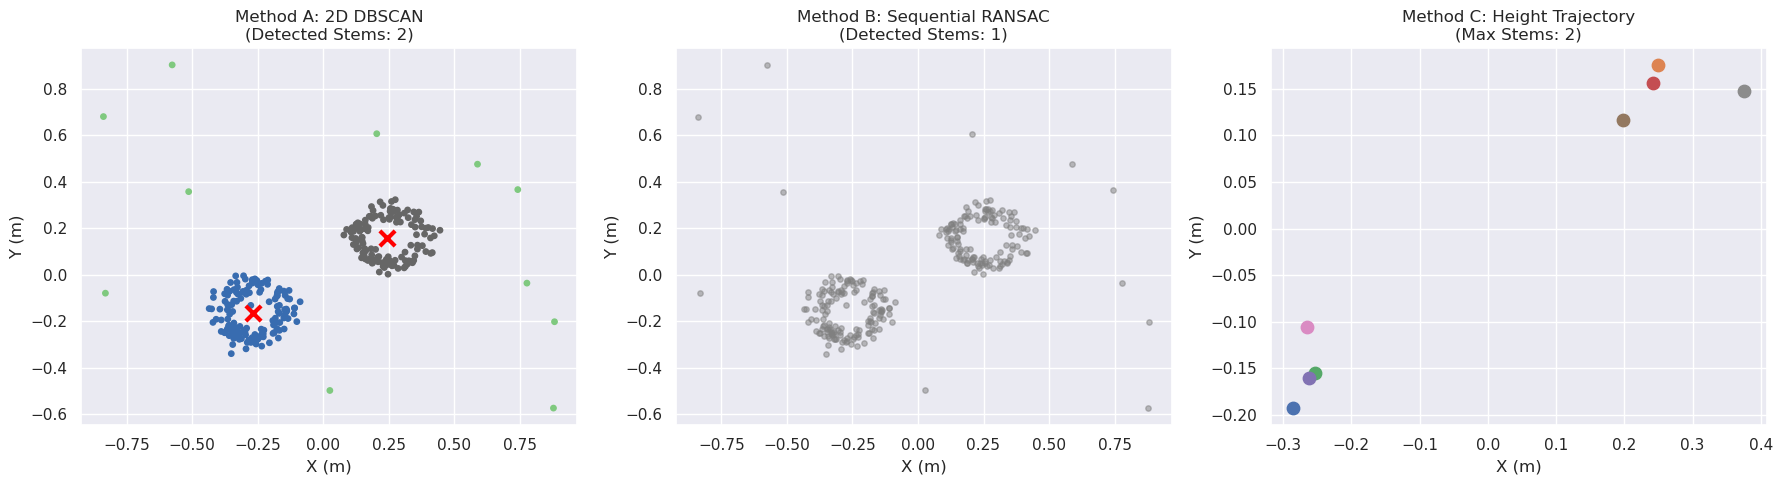

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Method A Plot (DBSCAN)
res = detect_multi_stems_dbscan(tree_double)
sl_pts = res["slice_pts"]
labels = res["labels"]

if sl_pts is not None and labels is not None:
    axes[0].scatter(sl_pts[:, 0], sl_pts[:, 1], c=labels, cmap="Accent", s=15)
    for c in res["centers"]:
        axes[0].scatter(c[0], c[1], color="red", marker="x", s=120, linewidth=3)
axes[0].set_title(f"Method A: 2D DBSCAN\n(Detected Stems: {res['stem_count']})")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")

# 2. Method B Plot (Sequential RANSAC)
res_b = detect_multi_stems_ransac(tree_double)
sl_pts_b = res_b["slice_pts"]
if sl_pts_b is not None:
    axes[1].scatter(sl_pts_b[:, 0], sl_pts_b[:, 1], color="gray", alpha=0.5, s=15)
    for idx, sinfo in enumerate(res_b["stems_info"]):
        cx, cy = sinfo["center"]
        r = sinfo["radius"]
        circle_patch = plt.Circle((cx, cy), r, color=plt.cm.tab10(idx), fill=False, linewidth=3, label=f"Stem #{idx+1} ({sinfo['dbh_cm']:.1f}cm)")
        axes[1].add_patch(circle_patch)
        axes[1].scatter(cx, cy, color=plt.cm.tab10(idx), marker="o", s=80)
    if res_b["stems_info"]:
        axes[1].legend()
axes[1].set_title(f"Method B: Sequential RANSAC\n(Detected Stems: {res_b['stem_count']})")
axes[1].set_xlabel("X (m)")
axes[1].set_ylabel("Y (m)")

# 3. Method C Plot (Trajectory Height Tracking)
res_c = detect_multi_stems_trajectory(tree_double)
for prof in res_c["height_profiles"]:
    h = prof["height_m"]
    for c in prof["centers"]:
        axes[2].scatter(c[0], c[1], label=f"h={h:.1f}m", s=80)
axes[2].set_title(f"Method C: Height Trajectory\n(Max Stems: {res_c['stem_count']})")
axes[2].set_xlabel("X (m)")
axes[2].set_ylabel("Y (m)")

plt.tight_layout()
plt.show()


## 6. Benchmarking Summary Table

Let's compare the performance of all 3 methods on single, double, and triple-stemmed test cases.


In [7]:
test_cases = [
    ("Single-Stem Tree", tree_single, 1),
    ("Double-Stem Tree", tree_double, 2),
    ("Triple-Stem Tree", tree_triple, 3)
]

results_table = []

for name, pts, gt_count in test_cases:
    mA = detect_multi_stems_dbscan(pts)
    mB = detect_multi_stems_ransac(pts)
    mC = detect_multi_stems_trajectory(pts)
    
    results_table.append({
        "Test Case": name,
        "Ground Truth Stems": gt_count,
        "Method A (DBSCAN)": mA["stem_count"],
        "Method A Correct?": "YES" if mA["stem_count"] == gt_count else "NO",
        "Method B (RANSAC)": mB["stem_count"],
        "Method B Correct?": "YES" if mB["stem_count"] == gt_count else "NO",
        "Method C (Trajectory)": mC["stem_count"],
        "Method C Correct?": "YES" if mC["stem_count"] == gt_count else "NO"
    })

df_benchmark = pd.DataFrame(results_table)
show_df(df_benchmark)


,Test Case,Ground Truth Stems,Method A (DBSCAN),Method A Correct?,Method B (RANSAC),Method B Correct?,Method C (Trajectory),Method C Correct?
0,Single-Stem Tree,1,1,YES,1,YES,1,YES
1,Double-Stem Tree,2,2,YES,1,NO,2,YES
2,Triple-Stem Tree,3,3,YES,1,NO,2,NO


## 7. Batch Analysis on Real LiDAR Point Cloud

If you have a real point cloud file (e.g. `results/canoa/parcelas/ff3d_full/classified_cloud.laz`), run the cell below to test all three methods across multiple tree instances.


In [8]:
REAL_CLOUD_PATH = "results/canoa/parcelas/ff3d_full/classified_cloud.laz"

if os.path.exists(REAL_CLOUD_PATH) and EUCALIPTO_AVAILABLE:
    print(f"Loading real point cloud: {REAL_CLOUD_PATH} ...")
    pts_real, extras_real, _ = load_cloud_auto(REAL_CLOUD_PATH)
    
    tree_id_col = next((c for c in ['instance_pred', 'treeID', 'tree_id', 'tree_id_label', 'segment_id'] if c in extras_real), None)
    if tree_id_col:
        t_ids = extras_real[tree_id_col]
        unique_tids = [tid for tid in np.unique(t_ids) if tid >= 0]
        print(f"Found {len(unique_tids)} segmented trees in cloud using column '{tree_id_col}'.")
        
        real_results = []
        for tid in unique_tids[:15]:
            t_pts = pts_real[t_ids == tid]
            res_a = detect_multi_stems_dbscan(t_pts)
            res_b = detect_multi_stems_ransac(t_pts)
            res_c = detect_multi_stems_trajectory(t_pts)
            
            real_results.append({
                "Tree ID": tid,
                "Points": len(t_pts),
                "Method A (DBSCAN) Stems": res_a["stem_count"],
                "Method B (RANSAC) Stems": res_b["stem_count"],
                "Method C (Trajectory) Stems": res_c["stem_count"]
            })
            
        show_df(pd.DataFrame(real_results))
    else:
        print("No tree_id / instance_pred column found in real cloud extra dimensions.")
else:
    print(f"File '{REAL_CLOUD_PATH}' not found or eucalipto module not installed. Skipping real cloud execution.")


Loading real point cloud: results/canoa/parcelas/ff3d_full/classified_cloud.laz ...
Found 28 segmented trees in cloud using column 'tree_id'.


/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:80: RuntimeWarning: divide by zero encountered in scalar divide
  mb = (P_rot[2, 1] - P_rot[1, 1]) / (P_rot[2, 0] - P_rot[1, 0])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:88: RuntimeWarning: invalid value encountered in scalar add
  ma * mb * (P_rot[0, 1] - P_rot[2, 1])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:79: RuntimeWarning: divide by zero encountered in scalar divide
  ma = (P_rot[1, 1] - P_rot[0, 1]) / (P_rot[1, 0] - P_rot[0, 0])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:87: RuntimeWarning: invalid value encountered in scalar divide
  p_center_x = (
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:80: RuntimeWarning: divide by zero encountered in scalar divide
  mb = (P_rot[2, 1] - P_rot[1, 1]) / (P_rot[2, 0] - P_rot[1, 0]

,Tree ID,Points,Method A (DBSCAN) Stems,Method B (RANSAC) Stems,Method C (Trajectory) Stems
0,0,1453,1,1,1
1,1,411,2,1,1
2,2,8929,1,1,1
3,3,7876,1,1,1
4,4,9449,1,1,1
5,5,12715,1,1,1
6,6,6506,2,1,1
7,7,4841,1,1,1
8,8,7818,1,1,1
9,10,10460,1,1,1


## 8. Single-Tree Deep-Dive Inspection & Diagnostics

Select any specific `TREE_ID_TO_INSPECT` from your point cloud below to generate complete 3D structure views, elevation projections, 2D slice fits, height trajectory profiles, and biometric summary diagnostics.


In [12]:
# ==========================================
# CONFIGURATION FOR SINGLE TREE INSPECTION
# ==========================================
INSPECT_CLOUD_PATH = "third_party/FF3D_inference/ff3d_forestsens/FF3D_oracle/bucket_out_folder/talhao_63_parcela_509fixedname_round2.ply"
TREE_ID_TO_INSPECT = 43  # Change this to any valid tree ID / instance_pred in your cloud!

# Slice parameters
Z_MIN_OFFSET = 1.8  # Height above base (m) - Set >= 1.8m to slice above the V-fork junction
Z_MAX_OFFSET = 3.0  # Height above base (m)
DBSCAN_EPS = 0.08   # DBSCAN distance threshold (m) - Lower value prevents connecting bridge points from merging stems

tree_pts = None
tree_pts_centered = None

if os.path.exists(INSPECT_CLOUD_PATH) and EUCALIPTO_AVAILABLE:
    pts_all, extras_all, _ = load_cloud_auto(INSPECT_CLOUD_PATH)
    tree_col = next((c for c in ['instance_pred', 'treeID', 'tree_id', 'tree_id_label', 'segment_id'] if c in extras_all), None)
    
    if tree_col:
        t_ids = extras_all[tree_col]
        tree_mask = (t_ids == TREE_ID_TO_INSPECT)
        tree_pts = pts_all[tree_mask]
        
        if len(tree_pts) > 0:
            print(f"Successfully loaded Tree ID {TREE_ID_TO_INSPECT} using column '{tree_col}' ({len(tree_pts)} points).")
            
            # Center tree X and Y coordinates for display
            tree_pts_centered = tree_pts.copy()
            tree_pts_centered[:, 0] -= np.median(tree_pts_centered[:, 0])
            tree_pts_centered[:, 1] -= np.median(tree_pts_centered[:, 1])
            tree_pts_centered[:, 2] -= tree_pts_centered[:, 2].min()
        else:
            print(f"Tree ID {TREE_ID_TO_INSPECT} not found! Available IDs: {[int(i) for i in np.unique(t_ids) if i>=0]}")
    else:
        print("No tree instance column found in cloud extra dimensions.")
else:
    print(f"Cloud path '{INSPECT_CLOUD_PATH}' not found. Using synthetic double-stem tree for inspection.")
    tree_pts = tree_double
    tree_pts_centered = tree_pts.copy()


Successfully loaded Tree ID 43 using column 'instance_pred' (27387 points).


### 8.1 3D Point Cloud Multi-Angle Structure
Visualizing the full 3D point cloud of the selected tree alongside Front Elevation (XZ) and Side Elevation (YZ) views to inspect trunk tilt, curvature, and branching.


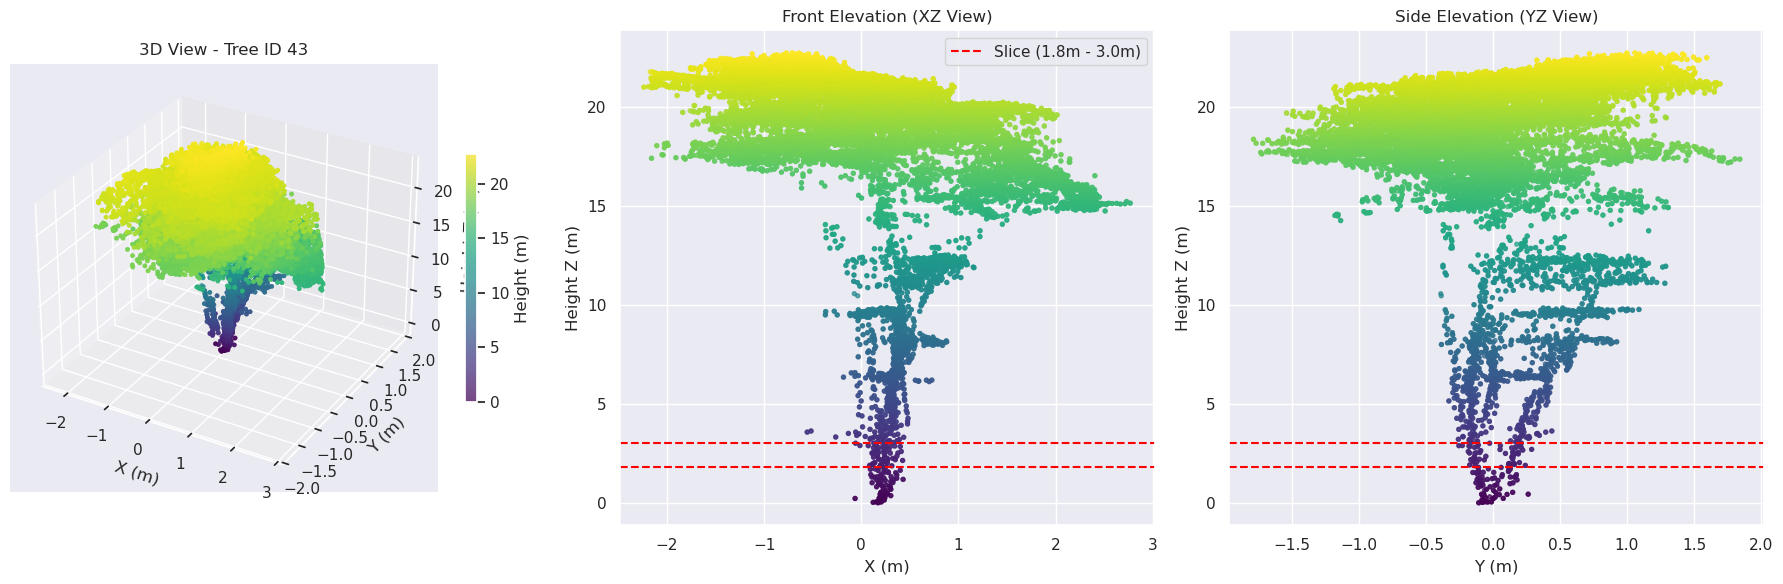

In [13]:
if tree_pts_centered is not None and len(tree_pts_centered) > 0:
    fig = plt.figure(figsize=(18, 6))
    
    # 1. 3D Scatter View
    ax1 = fig.add_subplot(1, 3, 1, projection='3d')
    scatter = ax1.scatter(tree_pts_centered[:, 0], tree_pts_centered[:, 1], tree_pts_centered[:, 2],
                          c=tree_pts_centered[:, 2], cmap='viridis', s=6, alpha=0.7)
    ax1.set_title(f"3D View - Tree ID {TREE_ID_TO_INSPECT}")
    ax1.set_xlabel("X (m)")
    ax1.set_ylabel("Y (m)")
    ax1.set_zlabel("Height Z (m)")
    fig.colorbar(scatter, ax=ax1, shrink=0.5, label='Height (m)')
    
    # 2. XZ Elevation (Front View)
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.scatter(tree_pts_centered[:, 0], tree_pts_centered[:, 2], c=tree_pts_centered[:, 2], cmap='viridis', s=8, alpha=0.7)
    ax2.set_title(f"Front Elevation (XZ View)")
    ax2.set_xlabel("X (m)")
    ax2.set_ylabel("Height Z (m)")
    ax2.axhline(Z_MIN_OFFSET, color='red', linestyle='--', label=f'Slice ({Z_MIN_OFFSET}m - {Z_MAX_OFFSET}m)')
    ax2.axhline(Z_MAX_OFFSET, color='red', linestyle='--')
    ax2.legend()
    
    # 3. YZ Elevation (Side View)
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.scatter(tree_pts_centered[:, 1], tree_pts_centered[:, 2], c=tree_pts_centered[:, 2], cmap='viridis', s=8, alpha=0.7)
    ax3.set_title(f"Side Elevation (YZ View)")
    ax3.set_xlabel("Y (m)")
    ax3.set_ylabel("Height Z (m)")
    ax3.axhline(Z_MIN_OFFSET, color='red', linestyle='--')
    ax3.axhline(Z_MAX_OFFSET, color='red', linestyle='--')
    
    plt.tight_layout()
    plt.show()


### 8.2 Single Tree Method Diagnostics & Fitted Circles
Running Method A (DBSCAN), Method B (RANSAC Circle Fitting), and Method C (Trajectory Profile) specifically on the chosen tree.


/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:79: RuntimeWarning: divide by zero encountered in scalar divide
  ma = (P_rot[1, 1] - P_rot[0, 1]) / (P_rot[1, 0] - P_rot[0, 0])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:87: RuntimeWarning: invalid value encountered in scalar divide
  p_center_x = (
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:80: RuntimeWarning: divide by zero encountered in scalar divide
  mb = (P_rot[2, 1] - P_rot[1, 1]) / (P_rot[2, 0] - P_rot[1, 0])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:88: RuntimeWarning: invalid value encountered in scalar add
  ma * mb * (P_rot[0, 1] - P_rot[2, 1])
/home/matheuspimenta/.conda/envs/euc/lib/python3.12/site-packages/pyransac3d/circle.py:64: RuntimeWarning: invalid value encountered in divide
  vecC = vecC / np.linalg.norm(vecC)
/home/matheuspimenta/.conda/envs/e

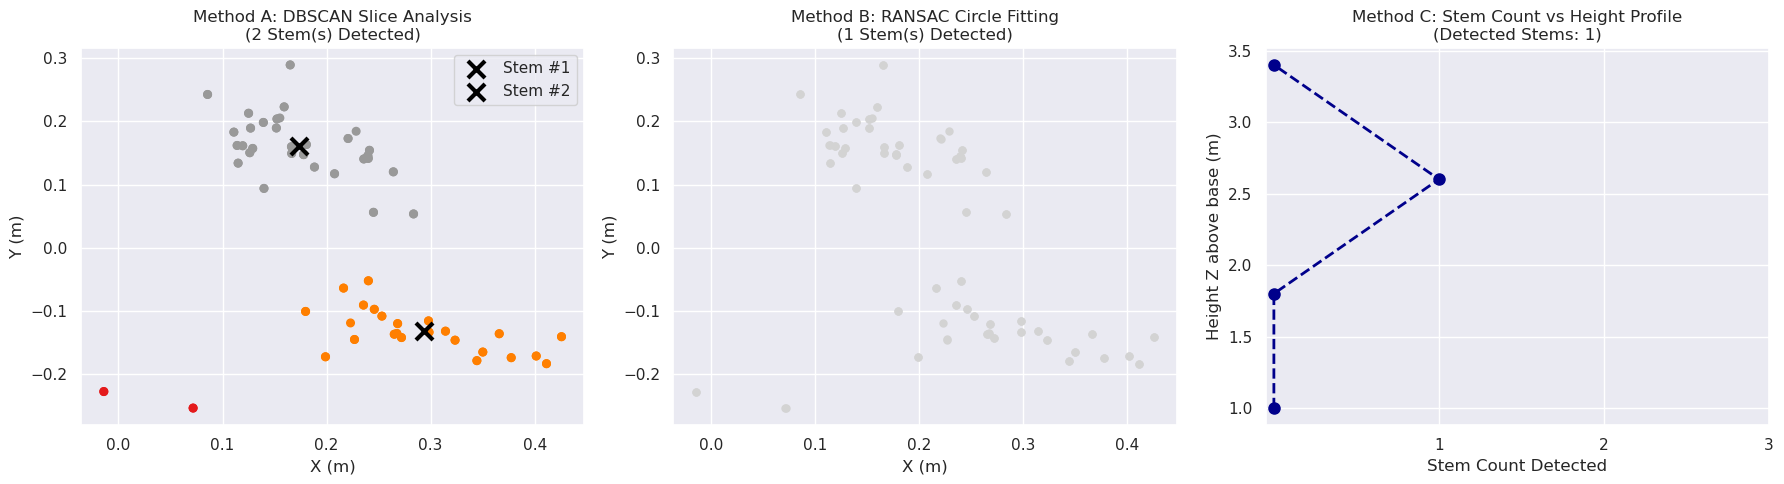

,Property / Metric,Value
0,Tree ID Inspected,43
1,Total Tree Points,27387
2,Bounding Height (m),22.75 m
3,Multi-Stem Classification,MULTIPLE BROTAÇÕES
4,Method A (DBSCAN) Stems,2
5,Method B (RANSAC) Stems,1
6,Method C (Trajectory) Stems,1
7,Estimated Stem DBHs (cm),N/A


In [14]:
if tree_pts_centered is not None and len(tree_pts_centered) > 0:
    res_a = detect_multi_stems_dbscan(tree_pts_centered, z_min_offset=Z_MIN_OFFSET, z_max_offset=Z_MAX_OFFSET, eps=DBSCAN_EPS)
    res_b = detect_multi_stems_ransac(tree_pts_centered, z_min_offset=Z_MIN_OFFSET, z_max_offset=Z_MAX_OFFSET)
    res_c = detect_multi_stems_trajectory(tree_pts_centered, eps=DBSCAN_EPS)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Method A: DBSCAN Clusters
    sl_a = res_a["slice_pts"]
    lbl_a = res_a["labels"]
    if sl_a is not None and lbl_a is not None:
        axes[0].scatter(sl_a[:, 0], sl_a[:, 1], c=lbl_a, cmap="Set1", s=30)
        for idx, c in enumerate(res_a["centers"]):
            axes[0].scatter(c[0], c[1], color="black", marker="x", s=150, linewidth=3, label=f"Stem #{idx+1}")
        axes[0].legend()
    axes[0].set_title(f"Method A: DBSCAN Slice Analysis\n({res_a['stem_count']} Stem(s) Detected)")
    axes[0].set_xlabel("X (m)")
    axes[0].set_ylabel("Y (m)")
    
    # Method B: Sequential RANSAC Circles
    sl_b = res_b["slice_pts"]
    if sl_b is not None:
        axes[1].scatter(sl_b[:, 0], sl_b[:, 1], color="lightgray", s=25)
        for idx, sinfo in enumerate(res_b["stems_info"]):
            cx, cy = sinfo["center"]
            r = sinfo["radius"]
            circle_patch = plt.Circle((cx, cy), r, color=plt.cm.tab10(idx), fill=False, linewidth=3,
                                      label=f"Stem #{idx+1}: DBH={sinfo['dbh_cm']:.1f}cm")
            axes[1].add_patch(circle_patch)
            axes[1].scatter(cx, cy, color=plt.cm.tab10(idx), marker="o", s=80)
        if res_b["stems_info"]:
            axes[1].legend()
    axes[1].set_title(f"Method B: RANSAC Circle Fitting\n({res_b['stem_count']} Stem(s) Detected)")
    axes[1].set_xlabel("X (m)")
    axes[1].set_ylabel("Y (m)")
    
    # Method C: Height Trajectory Profile
    profile_heights = [p["height_m"] for p in res_c["height_profiles"]]
    profile_counts = [p["stem_count"] for p in res_c["height_profiles"]]
    
    axes[2].plot(profile_counts, profile_heights, 'o--', color='darkblue', linewidth=2, markersize=8)
    axes[2].set_xticks(range(1, max(max(profile_counts, default=1) + 2, 4)))
    axes[2].set_title(f"Method C: Stem Count vs Height Profile\n(Detected Stems: {res_c['stem_count']})")
    axes[2].set_xlabel("Stem Count Detected")
    axes[2].set_ylabel("Height Z above base (m)")
    
    plt.tight_layout()
    plt.show()
    
    # Print Summary Diagnostics Table
    summary_data = {
        "Property / Metric": [
            "Tree ID Inspected",
            "Total Tree Points",
            "Bounding Height (m)",
            "Multi-Stem Classification",
            "Method A (DBSCAN) Stems",
            "Method B (RANSAC) Stems",
            "Method C (Trajectory) Stems",
            "Estimated Stem DBHs (cm)"
        ],
        "Value": [
            TREE_ID_TO_INSPECT,
            len(tree_pts),
            f"{tree_pts_centered[:, 2].max():.2f} m",
            "MULTIPLE BROTAÇÕES" if (res_a['is_multi_stem'] or res_b['is_multi_stem'] or res_c['is_multi_stem']) else "SINGLE STEM",
            res_a['stem_count'],
            res_b['stem_count'],
            res_c['stem_count'],
            ", ".join([f"{s['dbh_cm']:.1f}cm" for s in res_b['stems_info']]) if res_b['stems_info'] else "N/A"
        ]
    }
    show_df(pd.DataFrame(summary_data))
